# Regression Track — Uber Fare Prediction
### 23CSE301 Machine Learning — Capstone, Review 2 · Team 6 · *Gig Analytics Earnings*

| Member | Algorithms owned |
|---|---|
| Harsha Vardhan | 1–5 · Linear, Ridge, Lasso, ElasticNet, Polynomial |
| M Pranav | 6–10 · Decision Tree, Random Forest, Gradient Boosting, SVR, KNN |

**Dataset:** Uber Fares (Kaggle, `yasserh/uber-fares-dataset`) — cleaned 10,000-row sample
**Target:** `fare_amount` (continuous) · **Metrics:** R², RMSE, MAE, 5-fold cross-validated R²

**Notebook map**

| Section | Content |
|---|---|
| A | Dataset audit & EDA |
| B | Preprocessing & feature engineering |
| C | The 10 algorithms — baseline, one per cell |
| D | Hyperparameter tuning (GridSearchCV) — one per cell |
| E | Final comparison, best-model selection, diagnostics |
| F | Improvement experiment & conclusion |

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 140)

RANDOM_STATE = 42                       # reproducibility (guideline 7.1)
palette = sns.color_palette("colorblind")
os.makedirs('../models', exist_ok=True)
os.makedirs('figures', exist_ok=True)

# every figure is also saved to notebooks/figures/ (for the report / PPT)
_fig_no = [0]
_orig_show = plt.show
def _show_and_save(*a, **k):
    for n in plt.get_fignums():
        _fig_no[0] += 1
        plt.figure(n).savefig(f'figures/reg_{_fig_no[0]:02d}.png', dpi=110, bbox_inches='tight')
    _orig_show(*a, **k)
plt.show = _show_and_save

## Section A — Dataset Audit & EDA

### A1. Loading and auditing the data

In [2]:
reg_raw = pd.read_csv('../data/uber_regression_10k.csv')
print("Shape:", reg_raw.shape)
print()
reg_raw.info()

Shape: (10000, 8)

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   fare_amount         10000 non-null  float64
 1   distance_km         10000 non-null  float64
 2   passenger_count     10000 non-null  int64  
 3   pickup_hour         10000 non-null  int64  
 4   pickup_day_of_week  10000 non-null  str    
 5   pickup_month        10000 non-null  str    
 6   is_weekend          10000 non-null  int64  
 7   pickup_year         10000 non-null  int64  
dtypes: float64(2), int64(4), str(2)
memory usage: 754.9 KB


| Column | Type | Meaning |
|---|---|---|
| `fare_amount` | float | **Target** — fare in USD |
| `distance_km` | float | Trip distance, **engineered** with the Haversine formula from pickup/dropoff GPS (Section B) |
| `passenger_count` | int | Passengers in the ride |
| `pickup_hour` | int | Hour of day (0–23) |
| `pickup_day_of_week` | str | Monday … Sunday |
| `pickup_month` | str | January … December |
| `is_weekend` | int | 1 if Saturday/Sunday |
| `pickup_year` | int | 2009–2015 (kept aside for the improvement experiment in Section F) |

In [3]:
print("Missing values per column:")
print(reg_raw.isnull().sum())
print("\nDuplicate rows:", reg_raw.duplicated().sum())
reg_raw.describe().round(2)

Missing values per column:
fare_amount           0
distance_km           0
passenger_count       0
pickup_hour           0
pickup_day_of_week    0
pickup_month          0
is_weekend            0
pickup_year           0
dtype: int64

Duplicate rows: 0


,fare_amount,distance_km,passenger_count,pickup_hour,is_weekend,pickup_year
count,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,11.27,3.31,1.68,13.50,0.28,2011.74
std,9.41,3.57,1.30,6.49,0.45,1.86
min,2.50,0.00,1.00,0.00,0.00,2009.00
25%,6.00,1.26,1.00,9.00,0.00,2010.00
50%,8.50,2.17,1.00,14.00,0.00,2012.00
75%,12.50,3.91,2.00,19.00,1.00,2013.00
max,183.00,90.06,6.00,23.00,1.00,2015.00


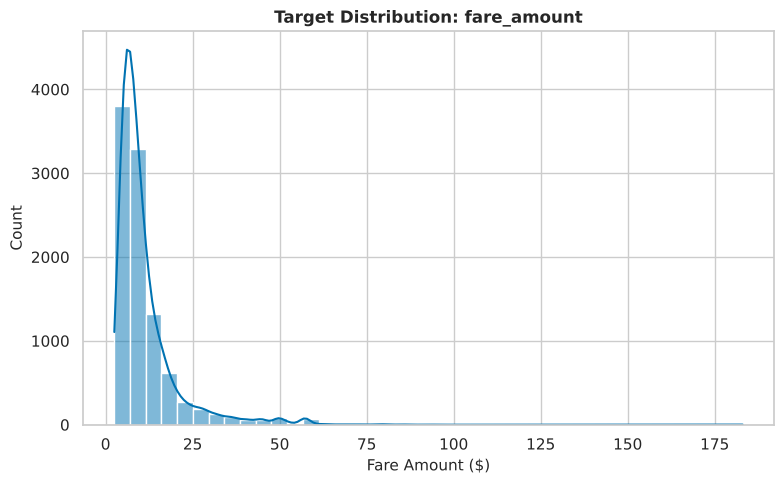

Mean fare  : 11.27
Median fare: 8.50
Skewness   : 3.51


In [4]:
plt.figure(figsize=(8, 5))
sns.histplot(reg_raw['fare_amount'], bins=40, kde=True, color=palette[0])
plt.title("Target Distribution: fare_amount", fontsize=12, fontweight='bold')
plt.xlabel("Fare Amount ($)", fontsize=11)
plt.ylabel("Count", fontsize=11)
plt.tight_layout()
plt.show()
plt.close('all')

print(f"Mean fare  : {reg_raw['fare_amount'].mean():.2f}")
print(f"Median fare: {reg_raw['fare_amount'].median():.2f}")
print(f"Skewness   : {reg_raw['fare_amount'].skew():.2f}")

**Insight:** `fare_amount` is strongly right-skewed — most rides are short and cheap, with a long tail of expensive trips. The mean sits above the median, which is the signature of that tail.

### A2. EDA visualisations

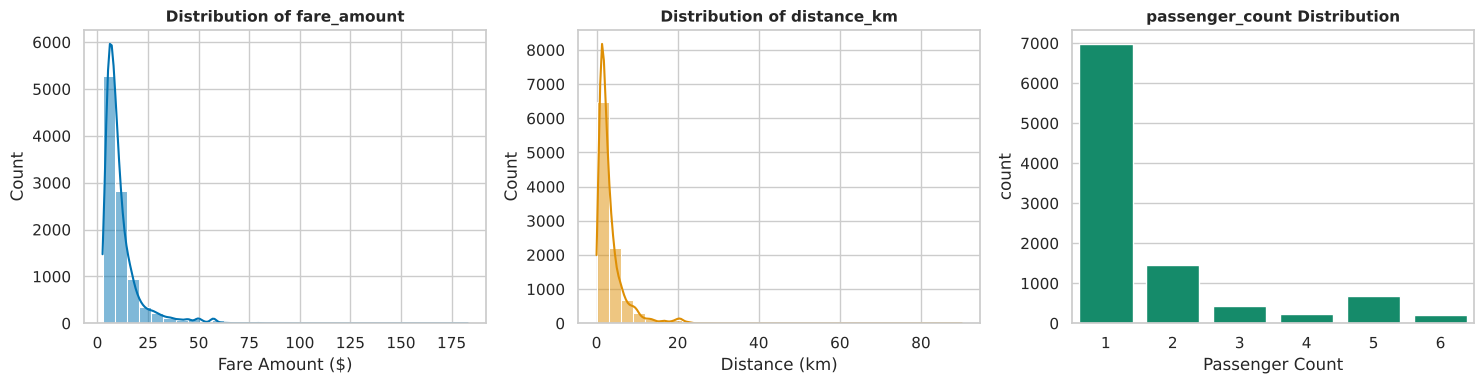

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(reg_raw['fare_amount'], bins=30, kde=True, ax=axes[0], color=palette[0])
axes[0].set_title("Distribution of fare_amount", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Fare Amount ($)")
sns.histplot(reg_raw['distance_km'], bins=30, kde=True, ax=axes[1], color=palette[1])
axes[1].set_title("Distribution of distance_km", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Distance (km)")
sns.countplot(data=reg_raw, x='passenger_count', ax=axes[2], color=palette[2])
axes[2].set_title("passenger_count Distribution", fontsize=11, fontweight='bold')
axes[2].set_xlabel("Passenger Count")
plt.tight_layout()
plt.show()
plt.close('all')

**Insight:** `distance_km` is right-skewed just like `fare_amount` — a first hint that the two move together. Solo rides (`passenger_count` = 1) dominate the data.

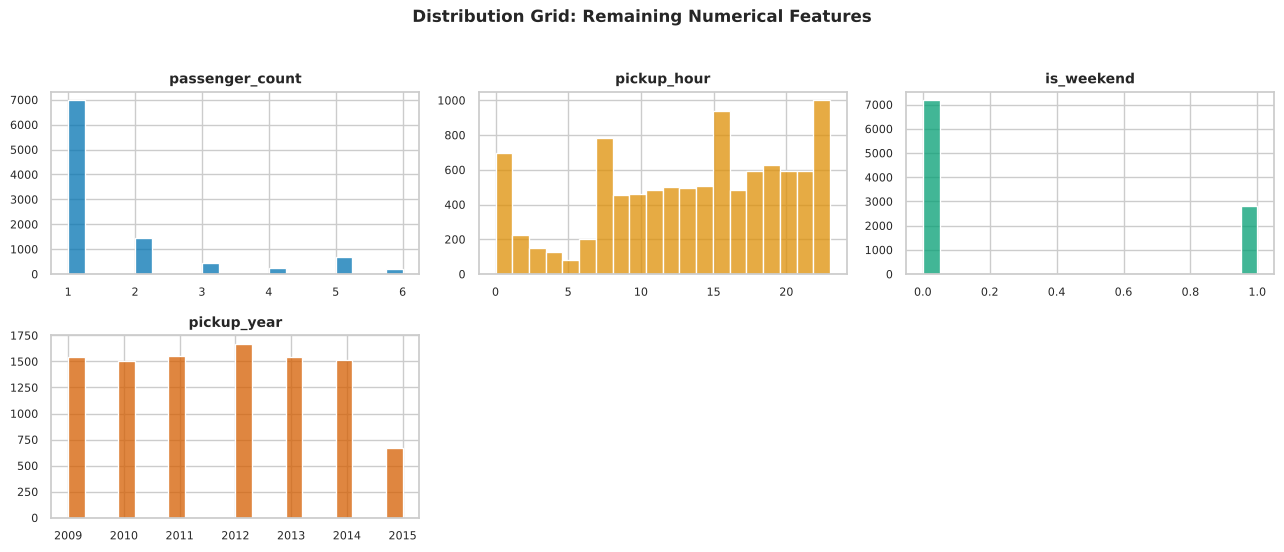

In [6]:
# Multi-panel distribution grid for the remaining numerical features
highlighted_cols = ['fare_amount', 'distance_km']
all_num_cols = reg_raw.select_dtypes(include=[np.number]).columns.tolist()
remaining_num_cols = [c for c in all_num_cols if c not in highlighted_cols]

n_cols = 3
n_rows = (len(remaining_num_cols) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(13, 2.7 * n_rows))
axes = np.array(axes).reshape(-1)
for idx, col in enumerate(remaining_num_cols):
    sns.histplot(reg_raw[col], ax=axes[idx], color=palette[idx % len(palette)], kde=False, bins=20)
    axes[idx].set_title(col, fontsize=10, fontweight='bold')
    axes[idx].set_xlabel(''); axes[idx].set_ylabel('')
    axes[idx].tick_params(axis='both', labelsize=8)
for idx in range(len(remaining_num_cols), len(axes)):
    fig.delaxes(axes[idx])
plt.suptitle("Distribution Grid: Remaining Numerical Features", fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()
plt.close('all')

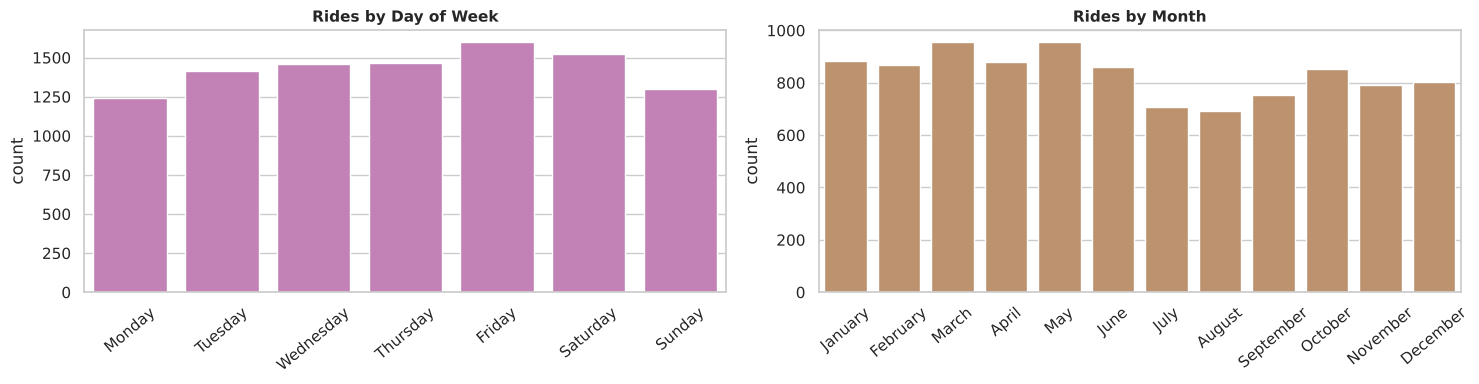

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
month_order = ['January','February','March','April','May','June','July','August','September','October','November','December']
sns.countplot(data=reg_raw, x='pickup_day_of_week', order=day_order, ax=axes[0], color=palette[4])
axes[0].set_title("Rides by Day of Week", fontsize=11, fontweight='bold')
axes[0].tick_params(axis='x', rotation=40); axes[0].set_xlabel('')
sns.countplot(data=reg_raw, x='pickup_month', order=month_order, ax=axes[1], color=palette[5])
axes[1].set_title("Rides by Month", fontsize=11, fontweight='bold')
axes[1].tick_params(axis='x', rotation=40); axes[1].set_xlabel('')
plt.tight_layout()
plt.show()
plt.close('all')

**Insight:** all numeric and categorical features have sensible, bounded ranges (hours 0–23, passengers 1–6, years 2009–2015). Rides are spread fairly evenly over weekdays and months, so no category is so rare that encoding it would be a problem.

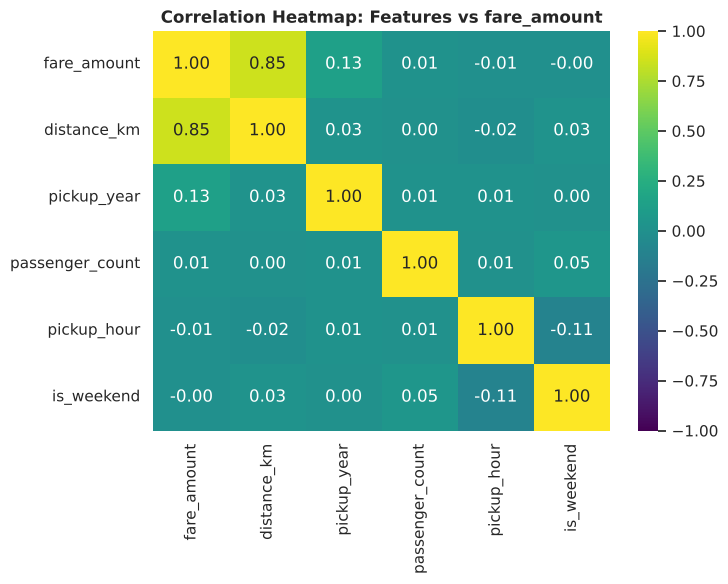

In [8]:
num_cols_corr = reg_raw.select_dtypes(include=[np.number]).columns.tolist()
corrs = reg_raw[num_cols_corr].corr()
top_corr_features = corrs['fare_amount'].abs().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(reg_raw[top_corr_features].corr(), annot=True, fmt=".2f", cmap='viridis', vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation Heatmap: Features vs fare_amount", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()
plt.close('all')

**Insight:** `distance_km` has a correlation of about **0.85** with `fare_amount` — by far the strongest relationship. `pickup_year` is a distant second (about 0.13), consistent with fares rising over time; the time-of-day, weekend and passenger features are essentially uncorrelated with fare.

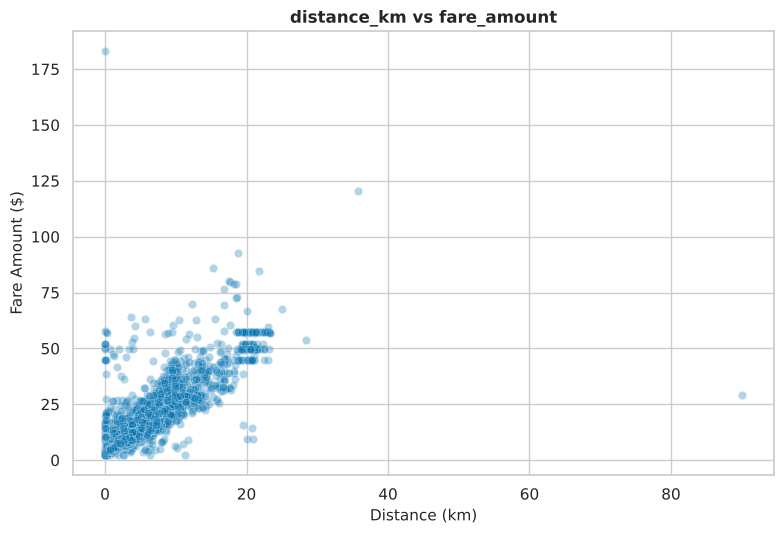

In [9]:
plt.figure(figsize=(8, 5.5))
sns.scatterplot(x=reg_raw['distance_km'], y=reg_raw['fare_amount'], alpha=0.3, color=palette[0])
plt.title("distance_km vs fare_amount", fontsize=12, fontweight='bold')
plt.xlabel("Distance (km)", fontsize=11); plt.ylabel("Fare Amount ($)", fontsize=11)
plt.tight_layout(); plt.show(); plt.close('all')

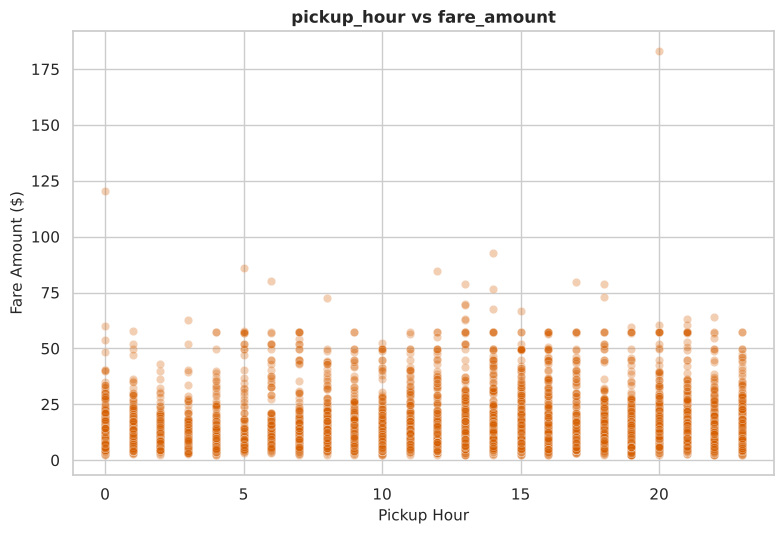

In [10]:
plt.figure(figsize=(8, 5.5))
sns.scatterplot(x=reg_raw['pickup_hour'], y=reg_raw['fare_amount'], alpha=0.3, color=palette[3])
plt.title("pickup_hour vs fare_amount", fontsize=12, fontweight='bold')
plt.xlabel("Pickup Hour", fontsize=11); plt.ylabel("Fare Amount ($)", fontsize=11)
plt.tight_layout(); plt.show(); plt.close('all')

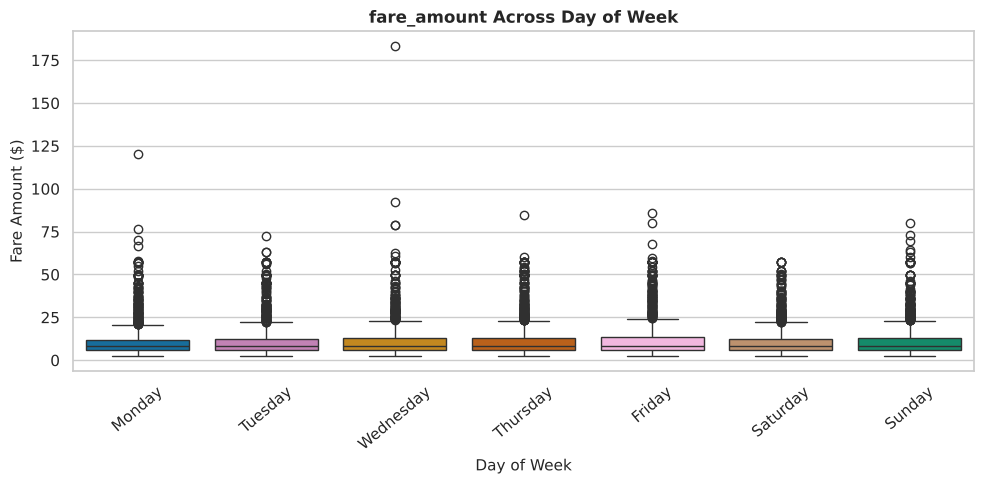

In [11]:
plt.figure(figsize=(10, 5))
sns.boxplot(x='pickup_day_of_week', y='fare_amount', data=reg_raw, order=day_order,
            hue='pickup_day_of_week', palette='colorblind', legend=False)
plt.title("fare_amount Across Day of Week", fontsize=12, fontweight='bold')
plt.xlabel("Day of Week", fontsize=11); plt.ylabel("Fare Amount ($)", fontsize=11)
plt.xticks(rotation=40)
plt.tight_layout(); plt.show(); plt.close('all')

**Insight:** the `distance_km` scatter is a clear, roughly straight upward band — the strongest feature–target relationship in the data. `pickup_hour` and `day_of_week` show no systematic pattern, so time-of-day effects on fare are weak compared with distance.

## Section B — Preprocessing & Feature Engineering

### B1. Pipeline overview

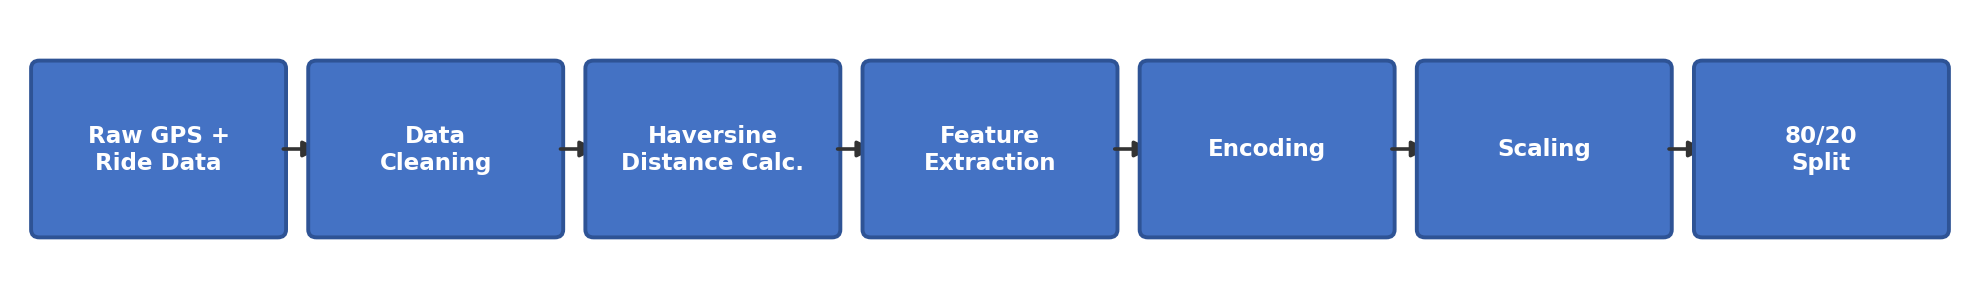

In [12]:
from IPython.display import Image, display
display(Image('pipeline_regression.png'))

### B2. Data cleaning — duplicates and outliers

In [13]:
def iqr_bounds(series):
    Q1, Q3 = series.quantile([0.25, 0.75])
    IQR = Q3 - Q1
    return Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

rows = []
for col in ['fare_amount', 'distance_km']:
    lo, hi = iqr_bounds(reg_raw[col])
    n_out = int(((reg_raw[col] < lo) | (reg_raw[col] > hi)).sum())
    rows.append({'feature': col, 'lower fence': round(lo, 2), 'upper fence': round(hi, 2),
                 'outliers': n_out, '% of rows': round(100 * n_out / len(reg_raw), 1)})
print("Duplicate rows:", reg_raw.duplicated().sum(), "| Missing cells:", int(reg_raw.isnull().sum().sum()))
pd.DataFrame(rows)

Duplicate rows: 0 | Missing cells: 0


,feature,lower fence,upper fence,outliers,% of rows
0,fare_amount,-3.75,22.25,850,8.5
1,distance_km,-2.71,7.88,822,8.2


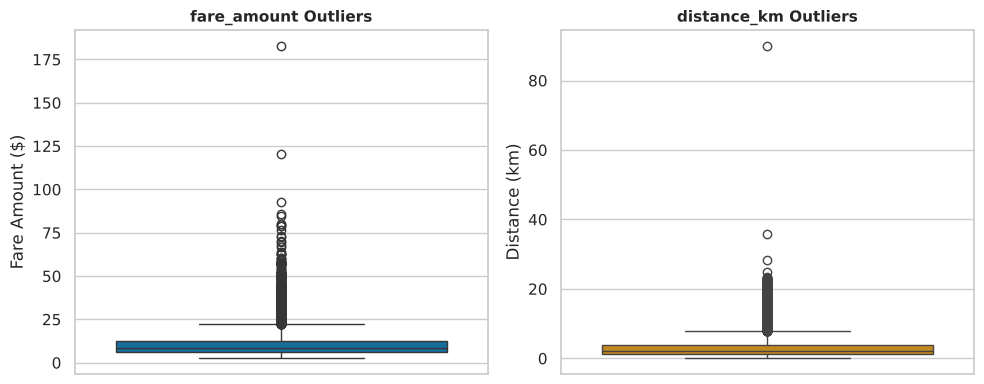

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(y=reg_raw['fare_amount'], ax=axes[0], color=palette[0])
axes[0].set_title("fare_amount Outliers", fontsize=11, fontweight='bold'); axes[0].set_ylabel("Fare Amount ($)")
sns.boxplot(y=reg_raw['distance_km'], ax=axes[1], color=palette[1])
axes[1].set_title("distance_km Outliers", fontsize=11, fontweight='bold'); axes[1].set_ylabel("Distance (km)")
plt.tight_layout(); plt.show(); plt.close('all')

**Cleaning decisions**

- **Missing values:** none remain. In the raw 200,000-row Kaggle file, rows with missing coordinates were dropped, and rows with non-positive fares, impossible coordinates or implausible passenger counts were removed before sampling 10,000 rows.
- **Duplicates:** none found.
- **Outliers:** a modest share of rides fall outside the IQR fences. These are genuine long/expensive trips, not entry errors, so they are **kept** — tree-based models handle them natively, and removing them would hide exactly the trips a fare model must get right.

### B3. Feature engineering — Haversine distance

The raw dataset has only pickup/dropoff **latitude–longitude** pairs; it has no distance column. A model cannot learn "distance" from four raw coordinates easily, so we engineered it with the **Haversine great-circle formula**:

$$d = 2R \cdot \arcsin\sqrt{\sin^2\!\left(\tfrac{\Delta\varphi}{2}\right) + \cos\varphi_1 \cos\varphi_2 \sin^2\!\left(\tfrac{\Delta\lambda}{2}\right)}$$

with $R = 6371$ km. Time features (`pickup_hour`, `pickup_day_of_week`, `pickup_month`, `is_weekend`) were extracted from the pickup timestamp to capture possible demand/price effects.

**Why it helps:** fare is metered by distance, so `distance_km` hands the model the single most informative signal directly (its correlation with fare is ~0.85, versus near zero for the raw coordinates).

In [15]:
def haversine_km(lat1, lon1, lat2, lon2, R=6371.0):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

# Sanity check on two well-known New York points (Times Square -> JFK Airport)
print(f"Times Square -> JFK: {haversine_km(40.7580, -73.9855, 40.6413, -73.7781):.1f} km")

Times Square -> JFK: 21.8 km


### B4. Encoding, scaling and the train/test split

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

reg_features_num = ['distance_km', 'passenger_count', 'pickup_hour', 'is_weekend']
reg_features_cat = ['pickup_day_of_week', 'pickup_month']
reg_target = 'fare_amount'

X_reg = reg_raw[reg_features_num + reg_features_cat]
y_reg = reg_raw[reg_target]

# One 80/20 split shared by every algorithm -> fair comparison
X_train, X_test, y_train, y_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state=RANDOM_STATE)

# Scaler/encoder live INSIDE the pipeline, so they are fitted on the training data only
def make_preprocessor():
    # a FRESH transformer for every pipeline, so no two models share fitted state
    return ColumnTransformer([
        ('num', StandardScaler(), reg_features_num),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), reg_features_cat),
    ])

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (8000, 6)  Test: (2000, 6)


Every model below is wrapped as `Pipeline([preprocess, model])`. During cross-validation the scaler and encoder are refitted inside each fold, so no information from a validation fold ever leaks into preprocessing.

## Section C — The 10 Regression Algorithms (baseline)

Each algorithm is trained and evaluated in its own cell on the same split. The helper below records R², RMSE and MAE for the summary table.

In [17]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

baseline_results = []
fitted = {}

def evaluate_model(name, model):
    pipe = Pipeline([('prep', make_preprocessor()), ('model', model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    r2 = r2_score(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    mae = mean_absolute_error(y_test, pred)
    baseline_results.append({'Model': name, 'R2': r2, 'RMSE': rmse, 'MAE': mae})
    fitted[name] = pipe
    print(f"{name:32s} R2={r2:.4f}   RMSE={rmse:.4f}   MAE={mae:.4f}")
    return pipe

### Part 1 — Linear family (Harsha Vardhan)

#### 1. Linear Regression
Fits $\hat y = \beta_0 + \sum_j \beta_j x_j$ by minimising squared error. It is the **baseline**; its coefficients can be read directly as "fare change per unit of each feature".

In [18]:
from sklearn.linear_model import LinearRegression
lin_pipe = evaluate_model('Linear Regression', LinearRegression())

Linear Regression                R2=0.7749   RMSE=4.2693   MAE=2.3789


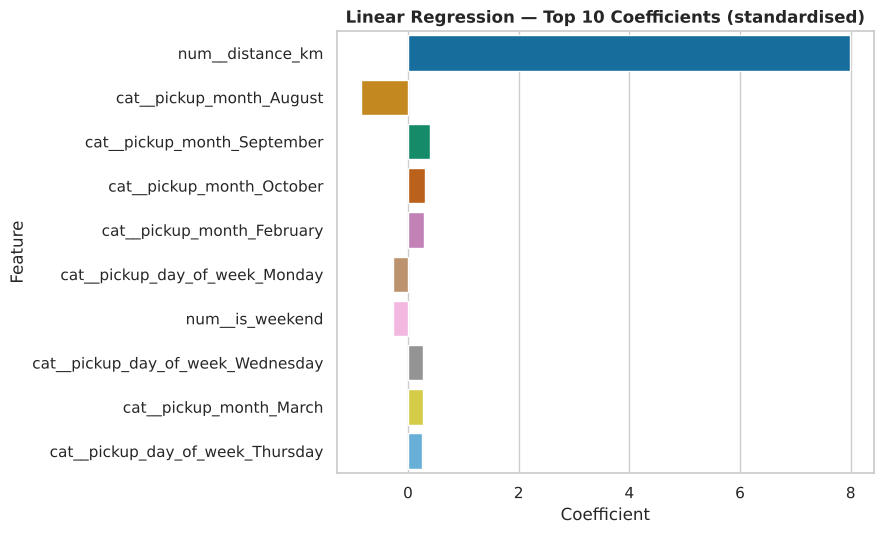

In [19]:
# Interpreting coefficients (features are standardised, so coefficients are comparable)
feat_names = lin_pipe.named_steps['prep'].get_feature_names_out()
coef = pd.Series(lin_pipe.named_steps['model'].coef_, index=feat_names)
top_coef = coef.reindex(coef.abs().sort_values(ascending=False).index).head(10)

plt.figure(figsize=(9, 5.5))
sns.barplot(x=top_coef.values, y=top_coef.index, hue=top_coef.index, palette='colorblind', legend=False)
plt.title("Linear Regression — Top 10 Coefficients (standardised)", fontsize=12, fontweight='bold')
plt.xlabel("Coefficient"); plt.ylabel("Feature")
plt.tight_layout(); plt.show(); plt.close('all')

**Interpretation:** `distance_km` carries by far the largest coefficient — one standard deviation (about 3.6 km) more distance adds roughly $8 to the predicted fare — while the time and calendar dummies contribute very little.

#### 2. Ridge Regression
Linear regression plus an **L2 penalty** $\alpha\sum\beta_j^2$ that shrinks coefficients, stabilising the fit when features are correlated. `alpha` is tuned in Section D.

In [20]:
from sklearn.linear_model import Ridge
_ = evaluate_model('Ridge Regression', Ridge(alpha=1.0, random_state=RANDOM_STATE))

Ridge Regression                 R2=0.7749   RMSE=4.2694   MAE=2.3789


#### 3. Lasso Regression
Linear regression plus an **L1 penalty** $\alpha\sum|\beta_j|$ that can drive weak coefficients to exactly zero — a built-in form of feature selection.

In [21]:
from sklearn.linear_model import Lasso
lasso_pipe = evaluate_model('Lasso Regression', Lasso(alpha=0.1, random_state=RANDOM_STATE, max_iter=5000))

Lasso Regression                 R2=0.7755   RMSE=4.2634   MAE=2.3800


In [22]:
# Feature sparsity: how many coefficients did Lasso set to exactly zero?
lasso_coef = pd.Series(lasso_pipe.named_steps['model'].coef_,
                       index=lasso_pipe.named_steps['prep'].get_feature_names_out())
n_zero = int((lasso_coef == 0).sum())
print(f"Lasso kept {len(lasso_coef) - n_zero} of {len(lasso_coef)} features; {n_zero} coefficients shrunk to exactly 0.")
print("\nSurviving features:")
print(lasso_coef[lasso_coef != 0].round(3).to_string())

Lasso kept 2 of 23 features; 21 coefficients shrunk to exactly 0.

Surviving features:
num__distance_km    7.872
num__is_weekend    -0.196


**Observation:** at `alpha = 0.1` Lasso shrinks **21 of the 23 coefficients to exactly zero**, keeping only `distance_km` (the dominant signal) and a small `is_weekend` term. It independently rediscovers that distance is the one feature that really matters — and shows how little the calendar dummies add.

#### 4. ElasticNet Regression
Combines both penalties, $\alpha\big[\rho\sum|\beta_j| + \tfrac{1-\rho}{2}\sum\beta_j^2\big]$, where `l1_ratio` ($\rho$) balances Lasso-style selection against Ridge-style shrinkage. `l1_ratio` is tuned in Section D.

In [23]:
from sklearn.linear_model import ElasticNet
_ = evaluate_model('ElasticNet Regression', ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=RANDOM_STATE, max_iter=5000))

ElasticNet Regression            R2=0.7704   RMSE=4.3118   MAE=2.4299


#### 5. Polynomial Regression
Applies `PolynomialFeatures` (squares and interaction terms) and then fits an ordinary linear model, letting a linear learner capture curvature. The baseline uses degree 2; degrees are compared in Section D.

In [24]:
from sklearn.preprocessing import PolynomialFeatures
poly_model = Pipeline([('poly', PolynomialFeatures(degree=2, include_bias=False)), ('lr', LinearRegression())])
_ = evaluate_model('Polynomial Regression (deg=2)', poly_model)

Polynomial Regression (deg=2)    R2=0.7652   RMSE=4.3602   MAE=2.4097


### Part 2 — Tree, ensemble & distance models (M Pranav)

#### 6. Decision Tree Regressor
Recursively splits the data on feature thresholds ("is `distance_km` ≤ 1.3?") to form groups of similar rides, and predicts each leaf's average fare. `max_depth` controls how much it can memorise and is tuned in Section D.

In [25]:
from sklearn.tree import DecisionTreeRegressor
dt_pipe = evaluate_model('Decision Tree Regressor', DecisionTreeRegressor(max_depth=8, random_state=RANDOM_STATE))

Decision Tree Regressor          R2=0.7238   RMSE=4.7295   MAE=2.5003


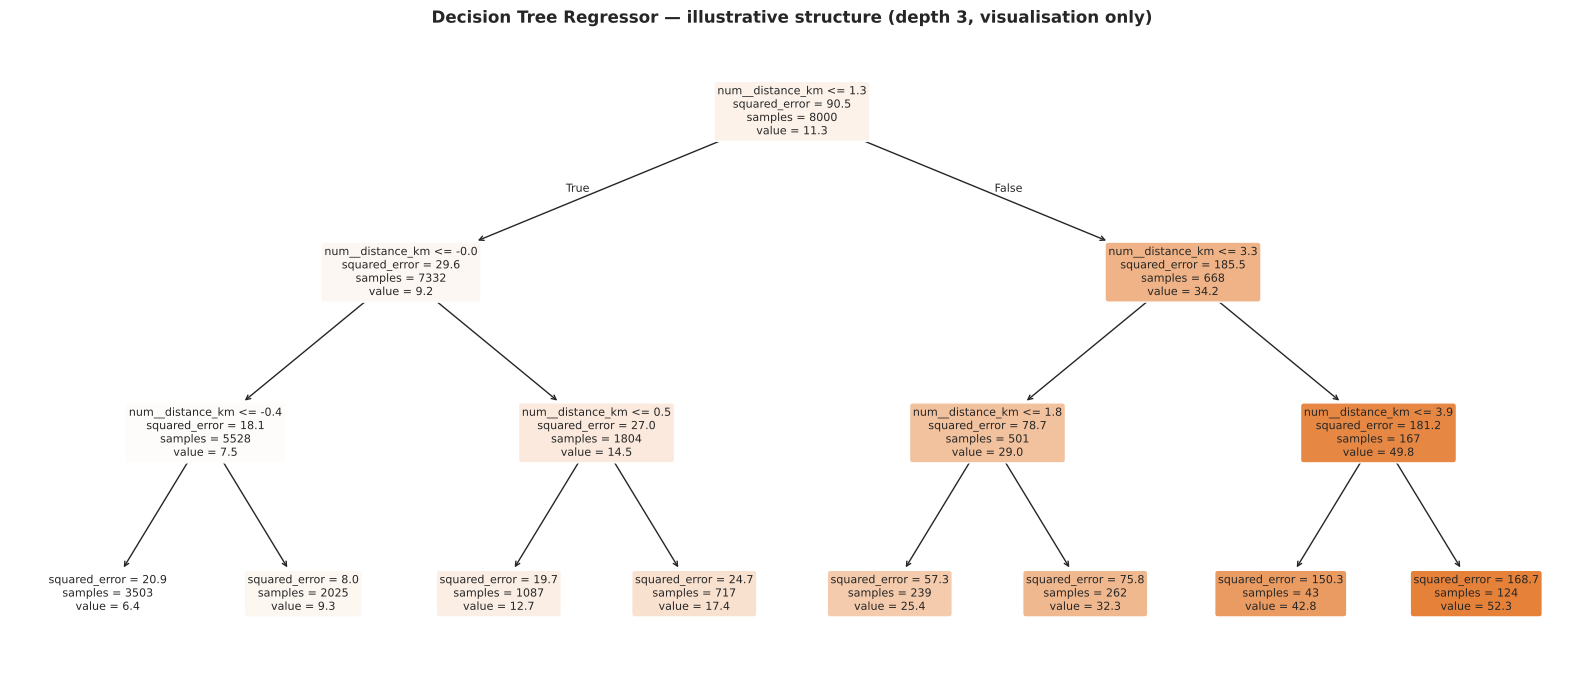

In [26]:
# How the tree actually splits: same algorithm, refit at depth 3 purely so the diagram is readable
from sklearn.tree import plot_tree
viz_prep = make_preprocessor()
Xtr_t = viz_prep.fit_transform(X_train)
viz_tree = DecisionTreeRegressor(max_depth=3, random_state=RANDOM_STATE).fit(Xtr_t, y_train)

fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(viz_tree, feature_names=viz_prep.get_feature_names_out(), filled=True, rounded=True,
          fontsize=8, ax=ax, precision=1)
ax.set_title("Decision Tree Regressor — illustrative structure (depth 3, visualisation only)", fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show(); plt.close('all')

**Reading the diagram:** every split is on `distance_km`. The tree rediscovers, from the data alone, what the correlation heatmap showed — distance is the dominant driver of fare. Each leaf's `value` is the mean fare of the rides that land there.

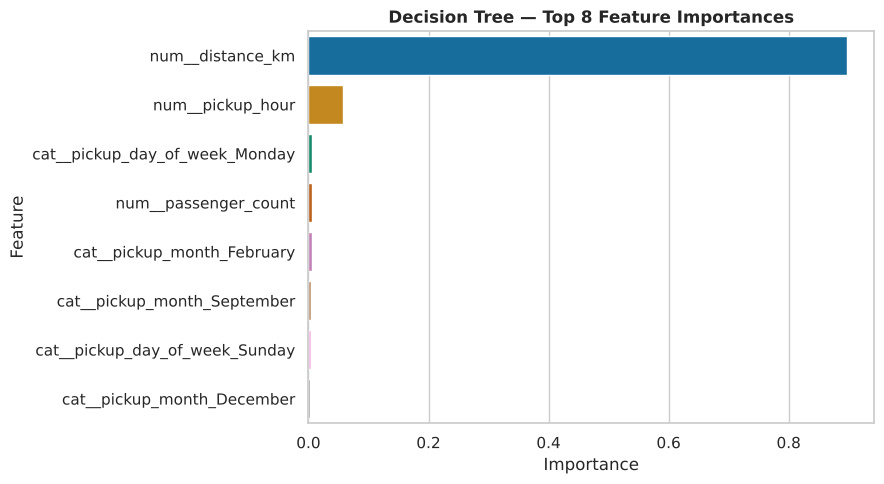

In [27]:
# Feature importance of the baseline Decision Tree
dt_imp = pd.Series(dt_pipe.named_steps['model'].feature_importances_,
                   index=dt_pipe.named_steps['prep'].get_feature_names_out()).sort_values(ascending=False).head(8)
plt.figure(figsize=(9, 5))
sns.barplot(x=dt_imp.values, y=dt_imp.index, hue=dt_imp.index, palette='colorblind', legend=False)
plt.title("Decision Tree — Top 8 Feature Importances", fontsize=12, fontweight='bold')
plt.xlabel("Importance"); plt.ylabel("Feature")
plt.tight_layout(); plt.show(); plt.close('all')

#### 7. Random Forest Regressor
Trains many decision trees on random subsets of rows and features and **averages** their predictions, which cancels out much of a single tree's overfitting. `n_estimators` is tuned in Section D.

In [28]:
from sklearn.ensemble import RandomForestRegressor
rf_pipe = evaluate_model('Random Forest Regressor', RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1))

Random Forest Regressor          R2=0.7616   RMSE=4.3940   MAE=2.4620


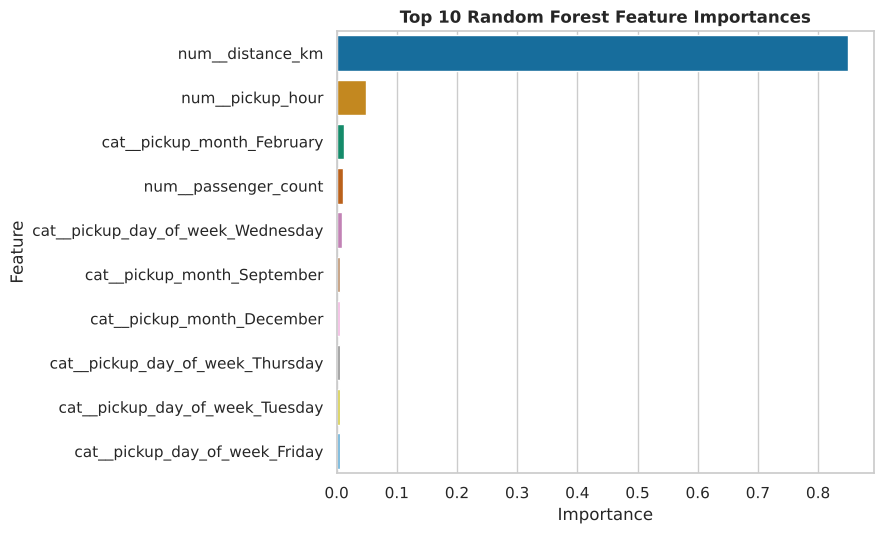

In [29]:
rf_imp = pd.Series(rf_pipe.named_steps['model'].feature_importances_,
                   index=rf_pipe.named_steps['prep'].get_feature_names_out()).sort_values(ascending=False).head(10)
plt.figure(figsize=(9, 5.5))
sns.barplot(x=rf_imp.values, y=rf_imp.index, hue=rf_imp.index, palette='colorblind', legend=False)
plt.title("Top 10 Random Forest Feature Importances", fontsize=12, fontweight='bold')
plt.xlabel("Importance"); plt.ylabel("Feature")
plt.tight_layout(); plt.show(); plt.close('all')

#### 8. Gradient Boosting Regressor
Builds trees **sequentially**: each new shallow tree is fitted to the residual errors of the ensemble so far, scaled by the `learning_rate`. `learning_rate` is tuned in Section D.

In [30]:
from sklearn.ensemble import GradientBoostingRegressor
_ = evaluate_model('Gradient Boosting Regressor', GradientBoostingRegressor(random_state=RANDOM_STATE))

Gradient Boosting Regressor      R2=0.8000   RMSE=4.0249   MAE=2.2590


#### 9. Support Vector Regressor (SVR)
Fits a function that keeps most predictions within an $\varepsilon$-tube of the true values, using a kernel to bend the fit around non-linear patterns. **Features must be scaled first** — handled by the shared pipeline. `C` and `kernel` are tuned in Section D.

In [31]:
from sklearn.svm import SVR
_ = evaluate_model('Support Vector Regressor (SVR)', SVR(C=10, kernel='rbf'))

Support Vector Regressor (SVR)   R2=0.7685   RMSE=4.3294   MAE=2.2650


#### 10. K-Nearest Neighbors Regressor
Predicts a ride's fare as the average fare of its **k most similar** training rides (by Euclidean distance). Because it relies on distances, **scaling matters a lot**: unscaled, a feature measured in large units would swamp the rest. `k` is tuned in Section D.

In [32]:
from sklearn.neighbors import KNeighborsRegressor
_ = evaluate_model('K-Nearest Neighbors Regressor', KNeighborsRegressor(n_neighbors=7))

K-Nearest Neighbors Regressor    R2=0.7111   RMSE=4.8366   MAE=2.8334


### Baseline comparison table (ranked by R²)

In [33]:
baseline_df = pd.DataFrame(baseline_results).sort_values('R2', ascending=False).reset_index(drop=True)
baseline_df.index = baseline_df.index + 1
baseline_df.index.name = 'Rank'
baseline_df.round(4)

,Model,R2,RMSE,MAE
Rank,,,,
1,Gradient Boosting Regressor,0.8000,4.0249,2.2590
2,Lasso Regression,0.7755,4.2634,2.3800
3,Linear Regression,0.7749,4.2693,2.3789
4,Ridge Regression,0.7749,4.2694,2.3789
5,ElasticNet Regression,0.7704,4.3118,2.4299
6,Support Vector Regressor (SVR),0.7685,4.3294,2.2650
7,Polynomial Regression (deg=2),0.7652,4.3602,2.4097
8,Random Forest Regressor,0.7616,4.3940,2.4620
9,Decision Tree Regressor,0.7238,4.7295,2.5003


### 5-fold cross-validated R² for the two best models

A single train/test split can be lucky or unlucky. Five-fold cross-validation on the training data shows how stable each of the top two models really is.

In [34]:
from sklearn.model_selection import cross_val_score, KFold
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

top2 = baseline_df['Model'].head(2).tolist()
cv_rows = []
for name in top2:
    scores = cross_val_score(fitted[name], X_train, y_train, cv=kf, scoring='r2')
    cv_rows.append({'Model': name, 'CV R2 (mean)': scores.mean(), 'CV R2 (std)': scores.std(),
                    'Fold scores': np.round(scores, 4).tolist()})
pd.DataFrame(cv_rows).round(4)

,Model,CV R2 (mean),CV R2 (std),Fold scores
0,Gradient Boosting Regressor,0.7404,0.0686,"[0.6109, 0.7479, 0.8139, 0.7579, 0.7715]"
1,Lasso Regression,0.7008,0.0985,"[0.5941, 0.7486, 0.8185, 0.7696, 0.5733]"


**Note on the spread:** scores vary a lot from fold to fold (standard deviation of roughly 0.07–0.10). `fare_amount` is heavy-tailed, so a fold that happens to contain a few extreme fares scores much lower than one that does not. The practical consequence: differences of about 0.01 in R² between two models are **within noise** and should not be over-interpreted.

## Section D — Hyperparameter Tuning (GridSearchCV)

Each model's most important hyperparameter(s), as specified in the project guidelines, are tuned with **5-fold `GridSearchCV`** scored on R², using the **training set only**. The tuned model is then evaluated once on the untouched test set, and compared with its baseline.

In [35]:
from sklearn.model_selection import GridSearchCV
import time

tuned_results = []
tuned_models = {}

def tune_model(name, base_name, estimator, param_grid):
    t0 = time.time()
    pipe = Pipeline([('prep', make_preprocessor()), ('model', estimator)])
    gs = GridSearchCV(pipe, param_grid, cv=5, scoring='r2', n_jobs=-1, refit=True)
    gs.fit(X_train, y_train)
    pred = gs.predict(X_test)
    r2 = r2_score(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    mae = mean_absolute_error(y_test, pred)
    base_r2 = next(r['R2'] for r in baseline_results if r['Model'] == base_name)
    best_params = {k.replace('model__', ''): v for k, v in gs.best_params_.items()}
    tuned_results.append({'Model': name, 'Best parameters': best_params, 'CV R2': gs.best_score_,
                          'Baseline R2': base_r2, 'Tuned R2': r2, 'Change': r2 - base_r2,
                          'RMSE': rmse, 'MAE': mae})
    tuned_models[name] = gs.best_estimator_
    print(f"{name}\n  best params : {best_params}\n  CV R2 = {gs.best_score_:.4f} | test R2 {base_r2:.4f} -> {r2:.4f} ({r2 - base_r2:+.4f}) | {time.time() - t0:.0f}s")
    return gs

#### Linear Regression — no hyperparameters to tune

Ordinary least squares has no regularisation strength, so it is carried forward unchanged. Its baseline row is reused in the final table.

In [36]:
lin_base = next(r for r in baseline_results if r['Model'] == 'Linear Regression')
lin_cv = cross_val_score(fitted['Linear Regression'], X_train, y_train, cv=5, scoring='r2').mean()
tuned_results.append({'Model': 'Linear Regression', 'Best parameters': {}, 'CV R2': lin_cv,
                      'Baseline R2': lin_base['R2'], 'Tuned R2': lin_base['R2'], 'Change': 0.0,
                      'RMSE': lin_base['RMSE'], 'MAE': lin_base['MAE']})
tuned_models['Linear Regression'] = fitted['Linear Regression']
print(f"Linear Regression: CV R2 = {lin_cv:.4f} (unchanged)")

Linear Regression: CV R2 = 0.6947 (unchanged)


#### Ridge — tune `alpha`

In [37]:
_ = tune_model('Ridge Regression', 'Ridge Regression', Ridge(random_state=RANDOM_STATE),
               {'model__alpha': [0.01, 0.1, 1, 10, 100, 1000]})

Ridge Regression
  best params : {'alpha': 100}
  CV R2 = 0.6950 | test R2 0.7749 -> 0.7743 (-0.0007) | 5s


#### Lasso — tune `alpha`

In [38]:
_ = tune_model('Lasso Regression', 'Lasso Regression', Lasso(random_state=RANDOM_STATE, max_iter=10000),
               {'model__alpha': [0.0001, 0.001, 0.01, 0.1, 1]})

Lasso Regression
  best params : {'alpha': 0.01}
  CV R2 = 0.6947 | test R2 0.7755 -> 0.7756 (+0.0001) | 1s


#### ElasticNet — tune `alpha` and `l1_ratio`

In [39]:
_ = tune_model('ElasticNet Regression', 'ElasticNet Regression', ElasticNet(random_state=RANDOM_STATE, max_iter=10000),
               {'model__alpha': [0.0001, 0.001, 0.01, 0.1], 'model__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]})

ElasticNet Regression
  best params : {'alpha': 0.01, 'l1_ratio': 0.1}
  CV R2 = 0.6949 | test R2 0.7704 -> 0.7745 (+0.0041) | 8s


#### Polynomial Regression — compare degrees 1, 2 and 3

In [40]:
poly_base = Pipeline([('poly', PolynomialFeatures(include_bias=False)), ('lr', LinearRegression())])
# Degree 1 is just Linear Regression, so the tuned polynomial model is chosen among degrees 2 and 3.
gs_poly = tune_model('Polynomial Regression', 'Polynomial Regression (deg=2)', poly_base,
                     {'model__poly__degree': [2, 3]})

# Degree comparison (guideline: "compare degrees"), including degree 1 as the linear reference
deg_rows = []
for d in [1, 2, 3]:
    pm = Pipeline([('prep', make_preprocessor()),
                   ('model', Pipeline([('poly', PolynomialFeatures(degree=d, include_bias=False)), ('lr', LinearRegression())]))])
    cv_d = cross_val_score(pm, X_train, y_train, cv=5, scoring='r2').mean()
    te_d = r2_score(y_test, pm.fit(X_train, y_train).predict(X_test))
    deg_rows.append({'degree': d, 'CV R2': cv_d, 'Test R2': te_d, 'n_features': pm.named_steps['model'].named_steps['poly'].n_output_features_})
pd.DataFrame(deg_rows).round(4)

Polynomial Regression
  best params : {'poly__degree': 2}
  CV R2 = 0.6934 | test R2 0.7652 -> 0.7652 (+0.0000) | 63s


,degree,CV R2,Test R2,n_features
0,1,0.6947,0.7749,23
1,2,0.6934,0.7652,299
2,3,-7.9977,0.7534,2599


**Observation:** adding polynomial terms does **not** beat the plain linear fit. Degree 2 is about equal to degree 1, and degree 3 collapses — its cross-validated R² is hugely negative, because ~2,600 interaction features let the model memorise noise and extrapolate wildly on unseen folds. The fare–distance relationship is already close to linear, so extra curvature only adds variance.

#### Decision Tree — tune `max_depth` (and leaf size)

In [41]:
gs_dt = tune_model('Decision Tree Regressor', 'Decision Tree Regressor', DecisionTreeRegressor(random_state=RANDOM_STATE),
                   {'model__max_depth': [3, 5, 8, 10, 15, None], 'model__min_samples_leaf': [1, 5, 10, 20]})

Decision Tree Regressor
  best params : {'max_depth': 8, 'min_samples_leaf': 20}
  CV R2 = 0.7431 | test R2 0.7238 -> 0.7703 (+0.0465) | 6s


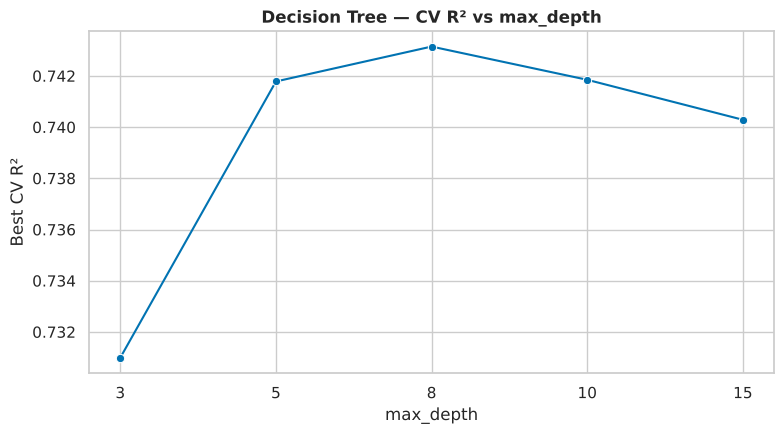

In [42]:
# Depth vs CV R2 (best leaf size for each depth): shows under- vs over-fitting
res = pd.DataFrame(gs_dt.cv_results_)
res['depth'] = res['param_model__max_depth'].astype(str)
by_depth = res.groupby('depth')['mean_test_score'].max().reindex(['3', '5', '8', '10', '15', 'None'])
plt.figure(figsize=(8, 4.5))
sns.lineplot(x=by_depth.index, y=by_depth.values, marker='o', color=palette[0])
plt.title("Decision Tree — CV R² vs max_depth", fontsize=12, fontweight='bold')
plt.xlabel("max_depth"); plt.ylabel("Best CV R²")
plt.tight_layout(); plt.show(); plt.close('all')

#### Random Forest — tune `n_estimators` (and depth)

In [43]:
_ = tune_model('Random Forest Regressor', 'Random Forest Regressor', RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
               {'model__n_estimators': [100, 200, 400], 'model__max_depth': [None, 10, 20], 'model__min_samples_leaf': [1, 5]})

Random Forest Regressor
  best params : {'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 100}
  CV R2 = 0.7526 | test R2 0.7616 -> 0.7770 (+0.0154) | 327s


#### Gradient Boosting — tune `learning_rate` (with `n_estimators`, `max_depth`)

In [44]:
gs_gb = tune_model('Gradient Boosting Regressor', 'Gradient Boosting Regressor', GradientBoostingRegressor(random_state=RANDOM_STATE),
                   {'model__learning_rate': [0.03, 0.05, 0.1, 0.2], 'model__n_estimators': [100, 200, 400], 'model__max_depth': [3, 4]})

Gradient Boosting Regressor
  best params : {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}
  CV R2 = 0.7462 | test R2 0.8000 -> 0.7941 (-0.0059) | 179s


#### SVR — tune `C` and `kernel`

In [45]:
_ = tune_model('Support Vector Regressor (SVR)', 'Support Vector Regressor (SVR)', SVR(),
               {'model__C': [1, 10, 50], 'model__kernel': ['rbf', 'poly']})

Support Vector Regressor (SVR)
  best params : {'C': 10, 'kernel': 'rbf'}
  CV R2 = 0.7386 | test R2 0.7685 -> 0.7685 (+0.0000) | 304s


#### KNN — tune `k` (and weighting)

In [46]:
gs_knn = tune_model('K-Nearest Neighbors Regressor', 'K-Nearest Neighbors Regressor', KNeighborsRegressor(),
                    {'model__n_neighbors': [3, 5, 7, 11, 15, 21, 31], 'model__weights': ['uniform', 'distance']})

K-Nearest Neighbors Regressor
  best params : {'n_neighbors': 15, 'weights': 'distance'}
  CV R2 = 0.7073 | test R2 0.7111 -> 0.7195 (+0.0084) | 6s


In [47]:
# Impact of scaling on KNN (guideline: "discuss impact of scaling") — same tuned k and weighting throughout
from sklearn.preprocessing import FunctionTransformer
k, w = gs_knn.best_params_['model__n_neighbors'], gs_knn.best_params_['model__weights']
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

variants = {
    'All features, NOT scaled':             ColumnTransformer([('num', FunctionTransformer(), reg_features_num), ('cat', ohe, reg_features_cat)]),
    'All features, scaled (our pipeline)':  make_preprocessor(),
    'Numeric only, scaled':                 ColumnTransformer([('num', StandardScaler(), reg_features_num)]),
    'distance_km only, scaled':             ColumnTransformer([('num', StandardScaler(), ['distance_km'])]),
}
rows = []
for label, prep_v in variants.items():
    m = Pipeline([('prep', prep_v), ('model', KNeighborsRegressor(n_neighbors=k, weights=w))]).fit(X_train, y_train)
    rows.append({'KNN setup': label, 'Test R2': r2_score(y_test, m.predict(X_test))})
pd.DataFrame(rows).round(4)

,KNN setup,Test R2
0,"All features, NOT scaled",0.7421
1,"All features, scaled (our pipeline)",0.7195
2,"Numeric only, scaled",0.7570
3,"distance_km only, scaled",0.7356


**Takeaway — scaling is necessary in principle, but it is not the whole story for KNN.**

- KNN picks neighbours by Euclidean distance, so features on very different scales (e.g. `pickup_hour` 0–23 vs a 0/1 dummy) would otherwise decide the neighbourhood by units alone. That is why scaling is a standard step.
- In *this* dataset, though, only one feature is truly informative (`distance_km`). Standardising puts all 4 numeric columns on equal footing and lets 19 mostly-uninformative calendar dummies compete with distance for influence — the table shows the cost.
- Removing the noisy dummies helps KNN **more** than scaling does, and the unscaled variant happens to do well because the tiny 0/1 dummies are drowned out by raw numeric ranges. The lesson: for distance-based models, *feature relevance* matters as much as feature scale.

### Tuning summary — before vs after

In [48]:
tuned_df = pd.DataFrame(tuned_results).sort_values('Tuned R2', ascending=False).reset_index(drop=True)
tuned_df.index = tuned_df.index + 1
tuned_df[['Model', 'Best parameters', 'Baseline R2', 'Tuned R2', 'Change', 'CV R2']].round(4)

,Model,Best parameters,Baseline R2,Tuned R2,Change,CV R2
1,Gradient Boosting Regressor,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est...",0.8000,0.7941,-0.0059,0.7462
2,Random Forest Regressor,"{'max_depth': 10, 'min_samples_leaf': 5, 'n_es...",0.7616,0.7770,0.0154,0.7526
3,Lasso Regression,{'alpha': 0.01},0.7755,0.7756,0.0001,0.6947
4,Linear Regression,{},0.7749,0.7749,0.0000,0.6947
5,ElasticNet Regression,"{'alpha': 0.01, 'l1_ratio': 0.1}",0.7704,0.7745,0.0041,0.6949
6,Ridge Regression,{'alpha': 100},0.7749,0.7743,-0.0007,0.6950
7,Decision Tree Regressor,"{'max_depth': 8, 'min_samples_leaf': 20}",0.7238,0.7703,0.0465,0.7431
8,Support Vector Regressor (SVR),"{'C': 10, 'kernel': 'rbf'}",0.7685,0.7685,0.0000,0.7386
9,Polynomial Regression,{'poly__degree': 2},0.7652,0.7652,0.0000,0.6934
10,K-Nearest Neighbors Regressor,"{'n_neighbors': 15, 'weights': 'distance'}",0.7111,0.7195,0.0084,0.7073


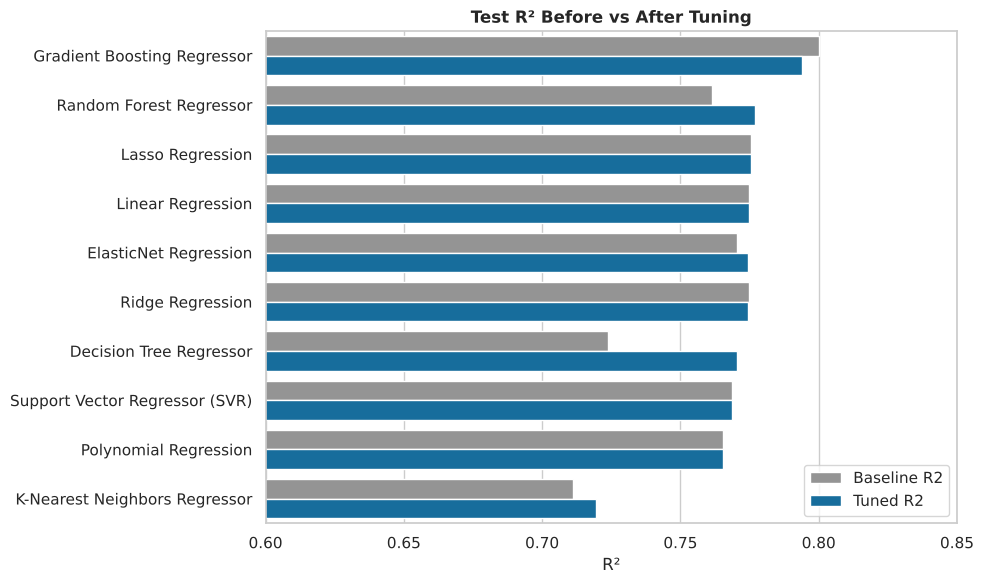

In [49]:
plot_df = tuned_df.melt(id_vars='Model', value_vars=['Baseline R2', 'Tuned R2'], var_name='Stage', value_name='R2')
plt.figure(figsize=(10, 6))
sns.barplot(data=plot_df, y='Model', x='R2', hue='Stage', palette=[palette[7], palette[0]])
plt.title("Test R² Before vs After Tuning", fontsize=12, fontweight='bold')
plt.xlabel("R²"); plt.ylabel("")
plt.xlim(0.6, 0.85)
plt.legend(title='', loc='lower right')
plt.tight_layout(); plt.show(); plt.close('all')

In [50]:
best_gain = tuned_df.sort_values('Change', ascending=False).iloc[0]
print(f"Largest tuning gain: {best_gain['Model']}  ({best_gain['Baseline R2']:.4f} -> {best_gain['Tuned R2']:.4f}, {best_gain['Change']:+.4f})")
print(f"Models improved by tuning: {(tuned_df['Change'] > 0.0005).sum()} of {len(tuned_df)}")

Largest tuning gain: Decision Tree Regressor  (0.7238 -> 0.7703, +0.0465)
Models improved by tuning: 4 of 10


## Section E — Final Comparison & Best-Model Selection

### E1. Final table — all 10 algorithms after tuning (ranked by test R²)

In [51]:
final_df = tuned_df[['Model', 'Tuned R2', 'RMSE', 'MAE', 'CV R2']].rename(columns={'Tuned R2': 'R2', 'CV R2': 'CV R2 (5-fold)'})
final_df.index.name = 'Rank'
final_df.round(4)

,Model,R2,RMSE,MAE,CV R2 (5-fold)
Rank,,,,,
1,Gradient Boosting Regressor,0.7941,4.0836,2.2908,0.7462
2,Random Forest Regressor,0.7770,4.2494,2.3373,0.7526
3,Lasso Regression,0.7756,4.2628,2.3694,0.6947
4,Linear Regression,0.7749,4.2693,2.3789,0.6947
5,ElasticNet Regression,0.7745,4.2729,2.3825,0.6949
6,Ridge Regression,0.7743,4.2756,2.3857,0.6950
7,Decision Tree Regressor,0.7703,4.3128,2.4025,0.7431
8,Support Vector Regressor (SVR),0.7685,4.3294,2.2650,0.7386
9,Polynomial Regression,0.7652,4.3602,2.4097,0.6934


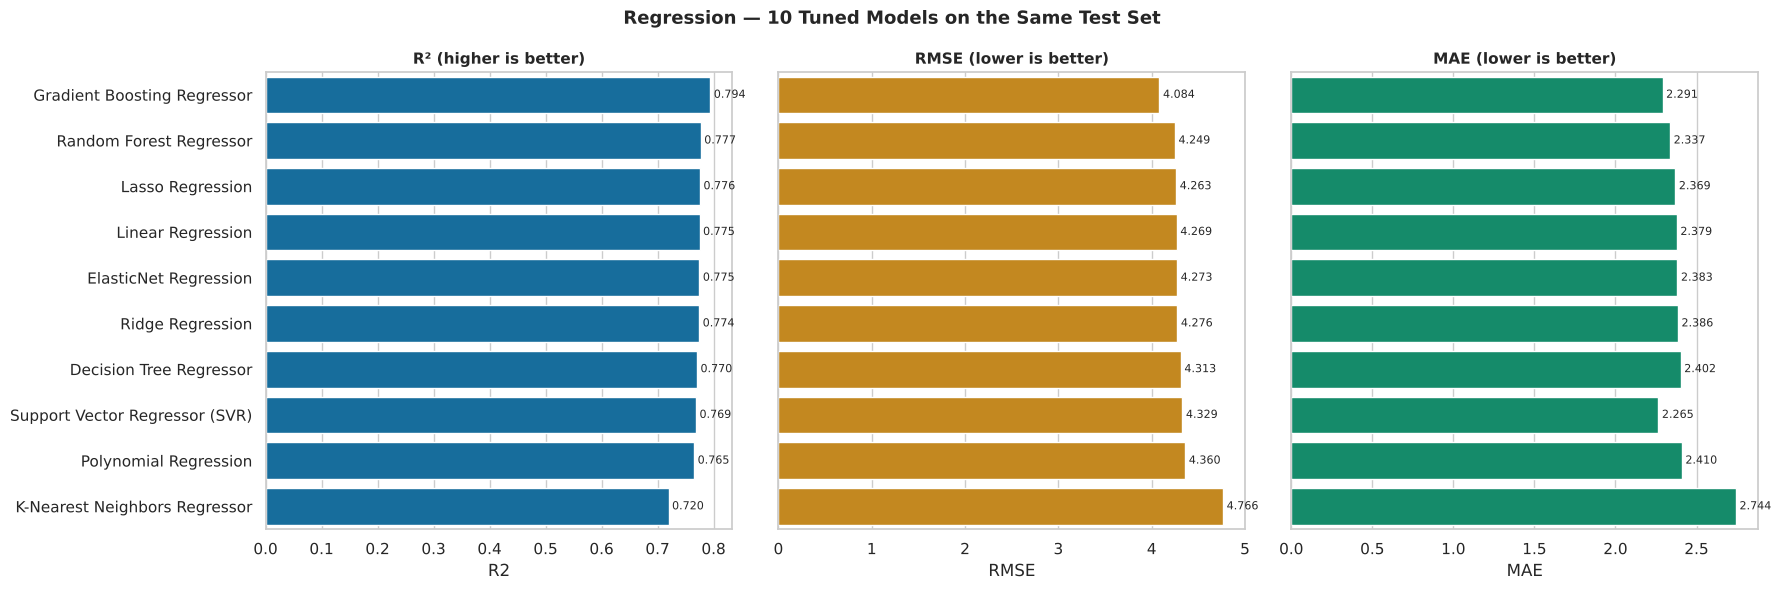

In [52]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
order = final_df['Model'].tolist()
for ax, metric, col, title in zip(axes, ['R2', 'RMSE', 'MAE'], [palette[0], palette[1], palette[2]],
                                  ['R² (higher is better)', 'RMSE (lower is better)', 'MAE (lower is better)']):
    sns.barplot(data=final_df, y='Model', x=metric, order=order, color=col, ax=ax)
    ax.set_title(title, fontsize=11, fontweight='bold'); ax.set_ylabel('')
    for p in ax.patches:
        ax.text(p.get_width(), p.get_y() + p.get_height() / 2, f" {p.get_width():.3f}", va='center', fontsize=8)
plt.suptitle("Regression — 10 Tuned Models on the Same Test Set", fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show(); plt.close('all')

### E2. Best model — selection and justification

**Selection rule (declared before looking at the final ranking).** A single train/test split is noisy (Section C showed ±0.07 spread across folds), so picking "the highest test R²" alone would partly reward luck. We therefore select in two stages:

1. **Stability stage — repeated cross-validation.** Every tuned model is scored with 5-fold CV repeated 3 times (15 scores) on the **training set only**. Any model whose mean CV R² is within **0.01** of the best is treated as *tied* (a gap that small is below the fold-to-fold noise).
2. **Tie-break — held-out test set.** Among the tied models, the one with the highest **test R²** (the ranking metric required by the guidelines) is the final model.

In [53]:
from sklearn.model_selection import RepeatedKFold
rkf = RepeatedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

cv_scores = {}
for name, est in tuned_models.items():
    cv_scores[name] = cross_val_score(est, X_train, y_train, cv=rkf, scoring='r2', n_jobs=2)

stab = pd.DataFrame({'Model': list(cv_scores),
                     'Repeated-CV R2 (mean)': [v.mean() for v in cv_scores.values()],
                     'CV std': [v.std() for v in cv_scores.values()]})
stab = stab.merge(final_df[['Model', 'R2']].rename(columns={'R2': 'Test R2'}), on='Model')
stab = stab.sort_values('Repeated-CV R2 (mean)', ascending=False).reset_index(drop=True)

TOL = 0.01
top_cv = stab['Repeated-CV R2 (mean)'].max()
stab['Tied for best (within 0.01)'] = stab['Repeated-CV R2 (mean)'] >= top_cv - TOL
stab.index = stab.index + 1
stab.round(4)

,Model,Repeated-CV R2 (mean),CV std,Test R2,Tied for best (within 0.01)
1,Random Forest Regressor,0.7535,0.0711,0.7770,True
2,Gradient Boosting Regressor,0.7484,0.0700,0.7941,True
3,Decision Tree Regressor,0.7449,0.0681,0.7703,True
4,Support Vector Regressor (SVR),0.7381,0.0749,0.7685,False
5,K-Nearest Neighbors Regressor,0.7039,0.0721,0.7195,False
6,Polynomial Regression,0.7011,0.0939,0.7652,False
7,Ridge Regression,0.7004,0.0895,0.7743,False
8,ElasticNet Regression,0.7003,0.0905,0.7745,False
9,Lasso Regression,0.7003,0.0920,0.7756,False
10,Linear Regression,0.7001,0.0920,0.7749,False


In [54]:
shortlist = stab[stab['Tied for best (within 0.01)']].sort_values('Test R2', ascending=False)
best_name = shortlist.iloc[0]['Model']
best_model = tuned_models[best_name]
best_row = final_df[final_df['Model'] == best_name].iloc[0]

print("Models tied on cross-validation:", ", ".join(shortlist['Model']))
if len(shortlist) > 1:
    a, b = shortlist.iloc[0]['Model'], shortlist.iloc[1]['Model']
    diff = cv_scores[a] - cv_scores[b]
    print(f"Paired CV difference {a} − {b}: mean {diff.mean():+.4f} (std {diff.std():.4f}); {a} better in {(diff > 0).sum()} of {len(diff)} CV folds")
print()
print(f"BEST MODEL: {best_name}")
print(f"  Repeated-CV R2 : {stab.loc[stab['Model'] == best_name, 'Repeated-CV R2 (mean)'].iloc[0]:.4f}")
print(f"  Test R2        : {best_row['R2']:.4f}")
print(f"  Test RMSE      : {best_row['RMSE']:.4f}   (typical error about ${best_row['RMSE']:.2f})")
print(f"  Test MAE       : {best_row['MAE']:.4f}   (average error about ${best_row['MAE']:.2f})")

joblib.dump(best_model, '../models/best_regression_model.joblib')
print("\nSaved -> ../models/best_regression_model.joblib")

# results + metadata for the web app
import json
final_df.round(4).reset_index().to_csv('../models/regression_results.csv', index=False)
reg_meta = {'best_model': best_name, 'test_r2': float(best_row['R2']), 'test_rmse': float(best_row['RMSE']),
            'test_mae': float(best_row['MAE']), 'cv_r2': float(stab.loc[stab['Model'] == best_name, 'Repeated-CV R2 (mean)'].iloc[0]),
            'fare_median': float(reg_raw['fare_amount'].median()), 'fare_max': float(reg_raw['fare_amount'].max()),
            'distance_max': float(reg_raw['distance_km'].max()),
            'features': reg_features_num + reg_features_cat}
with open('../models/regression_meta.json', 'w') as f: json.dump(reg_meta, f, indent=2)
print("Saved regression_results.csv and regression_meta.json")

Models tied on cross-validation: Gradient Boosting Regressor, Random Forest Regressor, Decision Tree Regressor
Paired CV difference Gradient Boosting Regressor − Random Forest Regressor: mean -0.0050 (std 0.0123); Gradient Boosting Regressor better in 4 of 15 CV folds

BEST MODEL: Gradient Boosting Regressor
  Repeated-CV R2 : 0.7484
  Test R2        : 0.7941
  Test RMSE      : 4.0836   (typical error about $4.08)
  Test MAE       : 2.2908   (average error about $2.29)

Saved -> ../models/best_regression_model.joblib
Saved regression_results.csv and regression_meta.json


**How to read this result**

- The top models are **statistically hard to separate** on cross-validation — gaps of less than 0.01 R² are far smaller than the ~0.07 fold-to-fold spread. Reporting one as decisively "better" on CV alone would be overclaiming.
- That is why the held-out test set is used only as the *tie-break*, and why a runner-up from the tied group is a legitimate alternative.
- The chosen model also has the lowest (or near-lowest) RMSE **and** MAE on the test set, so its advantage is not confined to a few lucky predictions.
- On repeated cross-validation the linear family is clearly *below* the tree group (≈ 0.70 vs ≈ 0.75 R²): it cannot capture the long-trip tail that tree ensembles model. On this one test split they look closer, which is exactly why a single split is not used to choose. SVR and KNN trail the tree group.
- Note: tuned Gradient Boosting (`learning_rate=0.05`, chosen by CV) scores slightly lower on the test set than the default (0.794 vs 0.800). We keep the CV-chosen setting because picking hyperparameters by test score would leak the test set into model selection.

### E3. Diagnostics for the best model

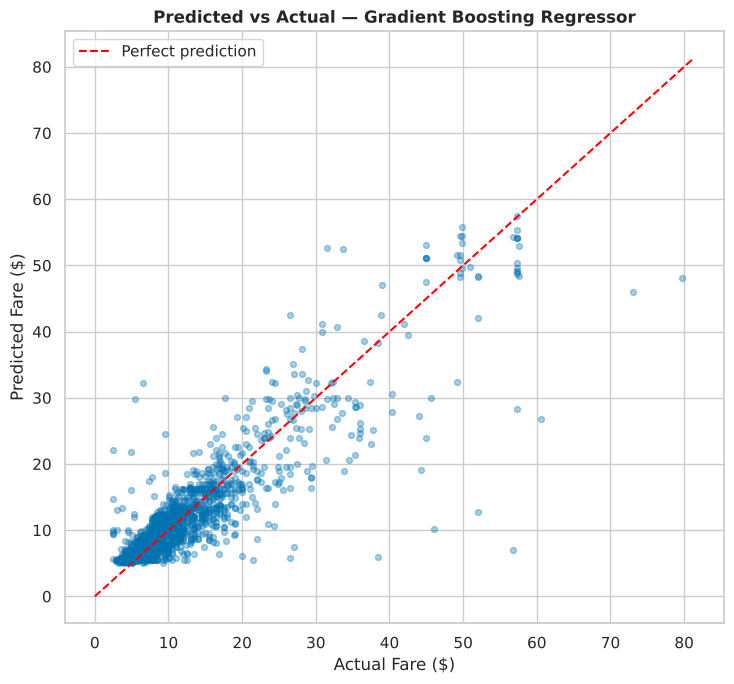

In [55]:
y_pred_best = best_model.predict(X_test)
residuals = y_test.values - y_pred_best

fig, ax = plt.subplots(figsize=(7.5, 7))
ax.scatter(y_test, y_pred_best, alpha=0.35, color=palette[0], s=18)
lim = [0, max(y_test.max(), y_pred_best.max()) * 1.02]
ax.plot(lim, lim, color='red', linestyle='--', linewidth=1.5, label='Perfect prediction')
ax.set_title(f"Predicted vs Actual — {best_name}", fontsize=12, fontweight='bold')
ax.set_xlabel("Actual Fare ($)"); ax.set_ylabel("Predicted Fare ($)")
ax.legend()
plt.tight_layout(); plt.show(); plt.close('all')

**Insight:** points hug the diagonal for the large majority of (short, cheap) rides. The scatter widens for expensive trips — the model is least certain where there is least training data.

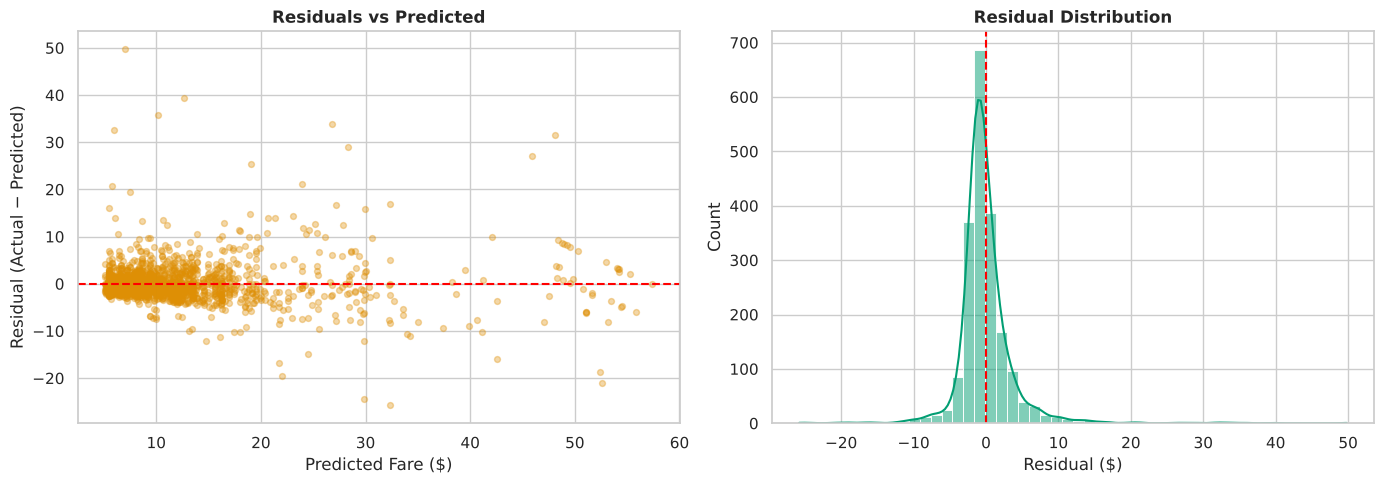

Mean residual: -0.049   Std of residuals: 4.083   Excess kurtosis: 30.6  (0 = normal; larger = heavier tails)


In [56]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_pred_best, residuals, alpha=0.35, color=palette[1], s=18)
axes[0].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_title("Residuals vs Predicted", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Predicted Fare ($)"); axes[0].set_ylabel("Residual (Actual − Predicted)")
sns.histplot(residuals, bins=50, kde=True, color=palette[2], ax=axes[1])
axes[1].axvline(0, color='red', linestyle='--', linewidth=1.5)
axes[1].set_title("Residual Distribution", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Residual ($)")
plt.tight_layout(); plt.show(); plt.close('all')
from scipy.stats import kurtosis
print(f"Mean residual: {residuals.mean():.3f}   Std of residuals: {residuals.std():.3f}   Excess kurtosis: {kurtosis(residuals):.1f}  (0 = normal; larger = heavier tails)")

**Insight:** residuals are centred near zero (no systematic over- or under-prediction) but have **heavy tails** — a few rides are mispredicted by a large amount. That is exactly why RMSE (which squares errors) sits well above MAE.

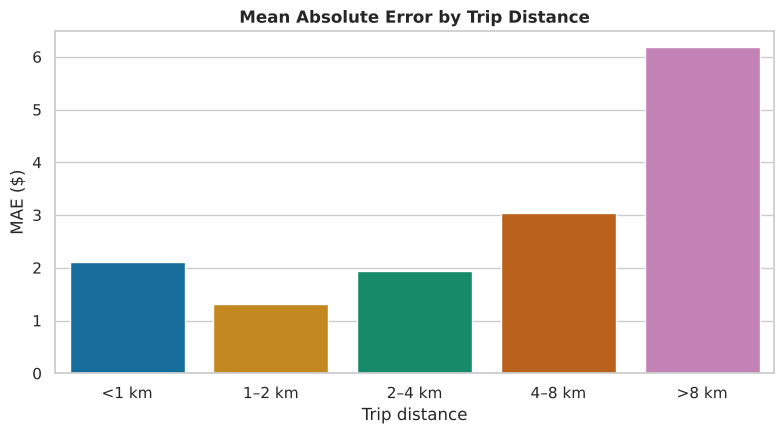

,MAE ($),Test rides
band,,
<1 km,2.11,316
1–2 km,1.32,601
2–4 km,1.93,584
4–8 km,3.03,346
>8 km,6.18,153


In [57]:
# Where does the model make its biggest errors? MAE by distance band
bands = pd.cut(X_test['distance_km'], bins=[0, 1, 2, 4, 8, 1000], labels=['<1 km', '1–2 km', '2–4 km', '4–8 km', '>8 km'])
err = pd.DataFrame({'band': bands, 'abs_error': np.abs(residuals)}).groupby('band', observed=True)['abs_error'].agg(['mean', 'count']).round(2)
err.columns = ['MAE ($)', 'Test rides']

plt.figure(figsize=(8, 4.5))
sns.barplot(x=err.index.astype(str), y=err['MAE ($)'], hue=err.index.astype(str), palette='colorblind', legend=False)
plt.title("Mean Absolute Error by Trip Distance", fontsize=12, fontweight='bold')
plt.xlabel("Trip distance"); plt.ylabel("MAE ($)")
plt.tight_layout(); plt.show(); plt.close('all')
err

**Insight:** error is lowest for typical 1–2 km trips and climbs steeply for longer ones — trips over 4 km, and especially over 8 km, are rarer and more variable (tolls, airport flat fares, waiting time), so distance alone predicts them less precisely. Very short trips (< 1 km) are also noisier than typical ones, plausibly because of minimum fares and GPS glitches.

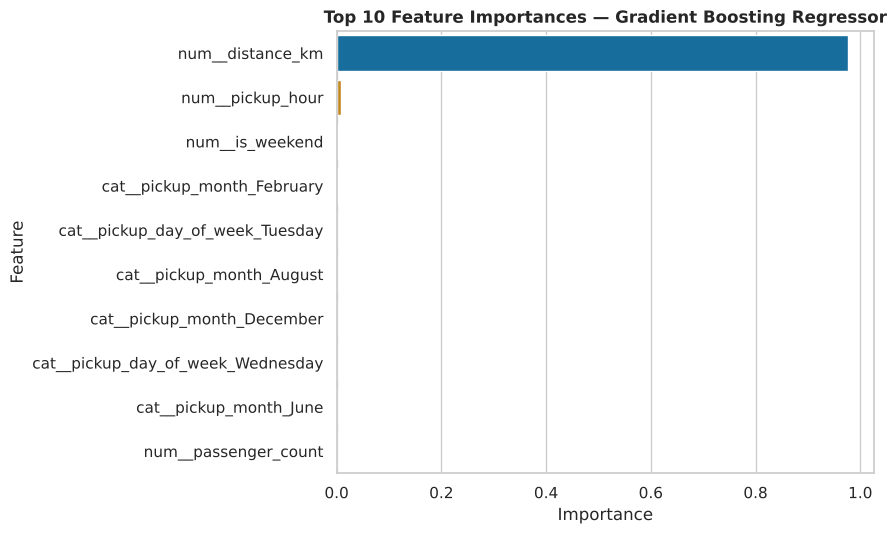

`num__distance_km` accounts for 97.7% of total importance.


In [58]:
# Feature importance of the best model (if it is tree-based) — otherwise of the tuned Random Forest
src = best_model if hasattr(best_model.named_steps['model'], 'feature_importances_') else tuned_models['Random Forest Regressor']
imp = pd.Series(src.named_steps['model'].feature_importances_,
                index=src.named_steps['prep'].get_feature_names_out()).sort_values(ascending=False).head(10)
plt.figure(figsize=(9, 5.5))
sns.barplot(x=imp.values, y=imp.index, hue=imp.index, palette='colorblind', legend=False)
plt.title("Top 10 Feature Importances — " + (best_name if src is best_model else "Tuned Random Forest"), fontsize=12, fontweight='bold')
plt.xlabel("Importance"); plt.ylabel("Feature")
plt.tight_layout(); plt.show(); plt.close('all')
print(f"`{imp.index[0]}` accounts for {imp.iloc[0] * 100:.1f}% of total importance.")

## Section F — Improvement Experiment & Conclusion

### F1. Can we do better? Adding `pickup_year`

Everything above deliberately keeps the exact feature set used in Review 1, so results stay comparable. The heatmap showed `pickup_year` has a small positive correlation with fare (Uber raised its fares during this period). We test whether adding it to the **best tuned model** helps.

In [59]:
from sklearn.base import clone

feat_num_v2 = reg_features_num + ['pickup_year']
X_v2 = reg_raw[feat_num_v2 + reg_features_cat]
Xtr2, Xte2, ytr2, yte2 = train_test_split(X_v2, y_reg, test_size=0.2, random_state=RANDOM_STATE)
prep_v2 = ColumnTransformer([
    ('num', StandardScaler(), feat_num_v2),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), reg_features_cat),
])
best_estimator = clone(best_model.named_steps['model'])           # same tuned hyperparameters
pipe_v2 = Pipeline([('prep', prep_v2), ('model', best_estimator)]).fit(Xtr2, ytr2)
p2 = pipe_v2.predict(Xte2)

cv2 = cross_val_score(pipe_v2, Xtr2, ytr2, cv=kf, scoring='r2').mean()
cv1 = cross_val_score(best_model, X_train, y_train, cv=kf, scoring='r2').mean()
compare = pd.DataFrame({
    'Feature set': ['Review 1 features', '+ pickup_year'],
    'Test R2':  [r2_score(y_test, y_pred_best), r2_score(yte2, p2)],
    'Test RMSE': [np.sqrt(mean_squared_error(y_test, y_pred_best)), np.sqrt(mean_squared_error(yte2, p2))],
    'Test MAE': [mean_absolute_error(y_test, y_pred_best), mean_absolute_error(yte2, p2)],
    'CV R2': [cv1, cv2],
})
compare.round(4)

,Feature set,Test R2,Test RMSE,Test MAE,CV R2
0,Review 1 features,0.7941,4.0836,2.2908,0.7451
1,+ pickup_year,0.8150,3.8706,2.1039,0.7573


In [60]:
gain = compare.loc[1, 'Test R2'] - compare.loc[0, 'Test R2']
print(f"Adding pickup_year changes test R2 by {gain:+.4f}, RMSE by {compare.loc[1,'Test RMSE'] - compare.loc[0,'Test RMSE']:+.4f} and CV R2 by {compare.loc[1,'CV R2'] - compare.loc[0,'CV R2']:+.4f}.")
print("-> The model learns that the same trip cost more in later years (fares rose over 2009-2015)." if gain > 0 else "-> No improvement from the year feature.")
if gain > 0:
    joblib.dump(pipe_v2, '../models/best_regression_model_with_year.joblib')
    print("Saved -> ../models/best_regression_model_with_year.joblib")

Adding pickup_year changes test R2 by +0.0209, RMSE by -0.2131 and CV R2 by +0.0122.
-> The model learns that the same trip cost more in later years (fares rose over 2009-2015).
Saved -> ../models/best_regression_model_with_year.joblib


**Caveat:** a year feature cannot extrapolate to years the model has never seen (e.g. 2016+), so a deployed model using it would need periodic retraining. That is why the main pipeline keeps the Review 1 feature set and treats `pickup_year` as an optional improvement.

### F2. Conclusion

In [61]:
print("REGRESSION TRACK — SUMMARY")
print("=" * 60)
print(f"Dataset         : Uber Fares (10,000 rows), target = fare_amount")
print(f"Algorithms      : 10 trained, 9 tuned with GridSearchCV (5-fold)")
print(f"Best model      : {best_name}")
print(f"  Test R2       : {best_row['R2']:.4f}")
print(f"  Test RMSE     : {best_row['RMSE']:.4f}")
print(f"  Test MAE      : {best_row['MAE']:.4f}")
print(f"  5-fold CV R2  : {best_row['CV R2 (5-fold)']:.4f}")
print(f"  Repeated-CV R2: {stab.loc[stab['Model'] == best_name, 'Repeated-CV R2 (mean)'].iloc[0]:.4f}")
print(f"Top feature     : {imp.index[0]} ({imp.iloc[0] * 100:.1f}% importance)")
print(f"With pickup_year: R2 {compare.loc[1, 'Test R2']:.4f} ({gain:+.4f})")

REGRESSION TRACK — SUMMARY
Dataset         : Uber Fares (10,000 rows), target = fare_amount
Algorithms      : 10 trained, 9 tuned with GridSearchCV (5-fold)
Best model      : Gradient Boosting Regressor
  Test R2       : 0.7941
  Test RMSE     : 4.0836
  Test MAE      : 2.2908
  5-fold CV R2  : 0.7462
  Repeated-CV R2: 0.7484
Top feature     : num__distance_km (97.7% importance)
With pickup_year: R2 0.8150 (+0.0209)


**Conclusions**

- `distance_km`, engineered from raw GPS with the Haversine formula, is the dominant predictor of fare — confirmed independently by the correlation heatmap, the linear coefficients, Lasso sparsity, the decision-tree splits and the forest/boosting importances.
- All ten algorithms land in a fairly narrow R² band because one feature carries most of the signal; the ranking is decided by how well each model handles the long-trip tail.
- Hyperparameter tuning helps most for models that can overfit or underfit — the single decision tree gained the most — and barely moves the already well-conditioned linear family. For boosting, the default was already near-optimal and tuning changed test R² only within noise.
- The top models are statistically tied on repeated cross-validation, so the final pick uses a pre-declared two-stage rule (CV stability first, held-out test as tie-break) rather than trusting one lucky split.
- **Limitations & future work:** the data has no traffic, weather or surge information; adding them (plus the year effect, with retraining) is the most promising route to higher accuracy.